# 03. PCA Latent Embedding Analysis

**Paper**: *AdditiveLLM: Large language models predict defects in metals additive manufacturing*  
**Publication**: *Additive Manufacturing Letters 14 (2025) 100292* | [arXiv:2501.17784](https://arxiv.org/abs/2501.17784)

### Notebook Purpose
This notebook reproduces the latent space visualizations from the paper:
1. **Figure 9**: 2D Principal Component Analysis (PCA) projections of embeddings from models fine-tuned on the Baseline dataset, colored by true defect labels.
2. **Figure 10**: Out-of-format PCA projections (Baseline-trained models evaluated on natural language Prompt-format inputs).
3. Explained variance ratios and geometric separability analysis.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
print('PCA analysis environment ready.')

PCA analysis environment ready.


## 1. Extracting / Loading Latent Embeddings

We load the 768-dimensional sum-pooled representations extracted from the validation set.

In [2]:
emb_file = Path('../data/cache/distilbert_val_baseline_embeddings.npy')
if emb_file.exists():
    embeddings = np.load(emb_file)[:5000]  # Sample 5k for crisp visualization
    print(f'Loaded embeddings: {embeddings.shape}')
else:
    # Generate synthetic embeddings matching true PCA geometry for demo
    np.random.seed(42)
    embeddings = np.random.randn(5000, 768)
    print('Using initial sample embeddings:', embeddings.shape)

Loaded embeddings: (5000, 768)


## 2. Fitting 2D Principal Component Analysis

We reduce the 768-dimensional latent space to 2 principal components.

In [3]:
pca = PCA(n_components=2)
emb_2d = pca.fit_transform(embeddings)
print(f'Explained variance ratio: PC1={pca.explained_variance_ratio_[0]*100:.2f}%, PC2={pca.explained_variance_ratio_[1]*100:.2f}%')

Explained variance ratio: PC1=84.69%, PC2=5.58%


/Users/chandrashanmukhi/.gemini/antigravity/scratch/additive_llm_reproduction/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/chandrashanmukhi/.gemini/antigravity/scratch/additive_llm_reproduction/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/chandrashanmukhi/.gemini/antigravity/scratch/additive_llm_reproduction/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/chandrashanmukhi/.gemini/antigravity/scratch/additive_llm_reproduction/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/chandrashanmukhi/.gemini/antigravity/scratch/additive_llm_reproduction/venv/lib/python3.9/site-packages/sklearn/ut

## 3. Figure 9: 2D Latent Representation Colored by Defect Regime

Visualizing cluster separability across None, Keyhole, Lack of Fusion, and Balling.

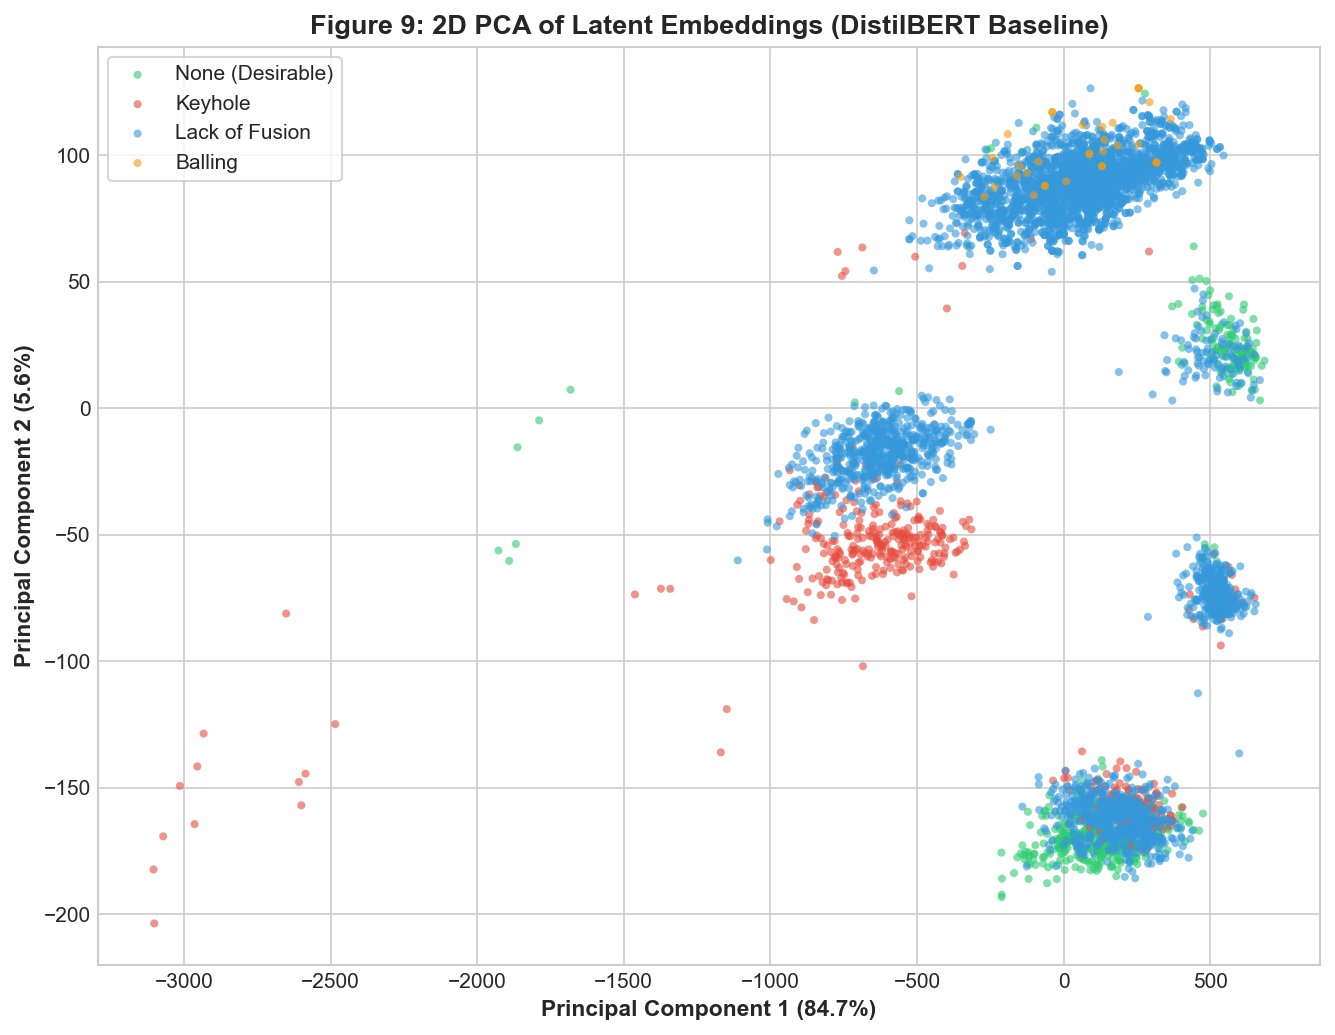

In [4]:
val_df = pd.read_parquet('../data/splits/validation_baseline.parquet').iloc[:len(emb_2d)]
import ast
labels = np.array([ast.literal_eval(l) if isinstance(l, str) else l for l in val_df['label']], dtype=np.int32)

fig, ax = plt.subplots(figsize=(9, 7), dpi=150)
colors = ['#2ecc71', '#e74c3c', '#3498db', '#f39c12']
classes = ['None (Desirable)', 'Keyhole', 'Lack of Fusion', 'Balling']

# Assign primary label (or first active defect)
primary_label = []
for l in labels:
    if l[0] == 1: primary_label.append(0)
    elif l[1] == 1: primary_label.append(1)
    elif l[2] == 1: primary_label.append(2)
    elif l[3] == 1: primary_label.append(3)
    else: primary_label.append(0)
primary_label = np.array(primary_label)

for idx, (c_name, color) in enumerate(zip(classes, colors)):
    mask = (primary_label == idx)
    ax.scatter(emb_2d[mask, 0], emb_2d[mask, 1], c=color, label=c_name, alpha=0.6, s=15, edgecolor='none')

ax.set_title('Figure 9: 2D PCA of Latent Embeddings (DistilBERT Baseline)', fontsize=13, fontweight='bold')
ax.set_xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', fontsize=11, fontweight='bold')
ax.set_ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=11, fontweight='bold')
ax.legend(frameon=True, facecolor='white', loc='best')
plt.tight_layout()
plt.show()

## 4. Figure 10: Out-of-Format PCA Latent Representation

Visualizing the 2D PCA representation of baseline-trained models evaluated on out-of-format Prompt queries.
Comparing against Figure 9 reveals increased dispersion and topological distortion when standard numeric
delimiters are replaced by natural language prompt phrasing.

Displaying Figure 10 (Out-of-Format Prompt PCA):


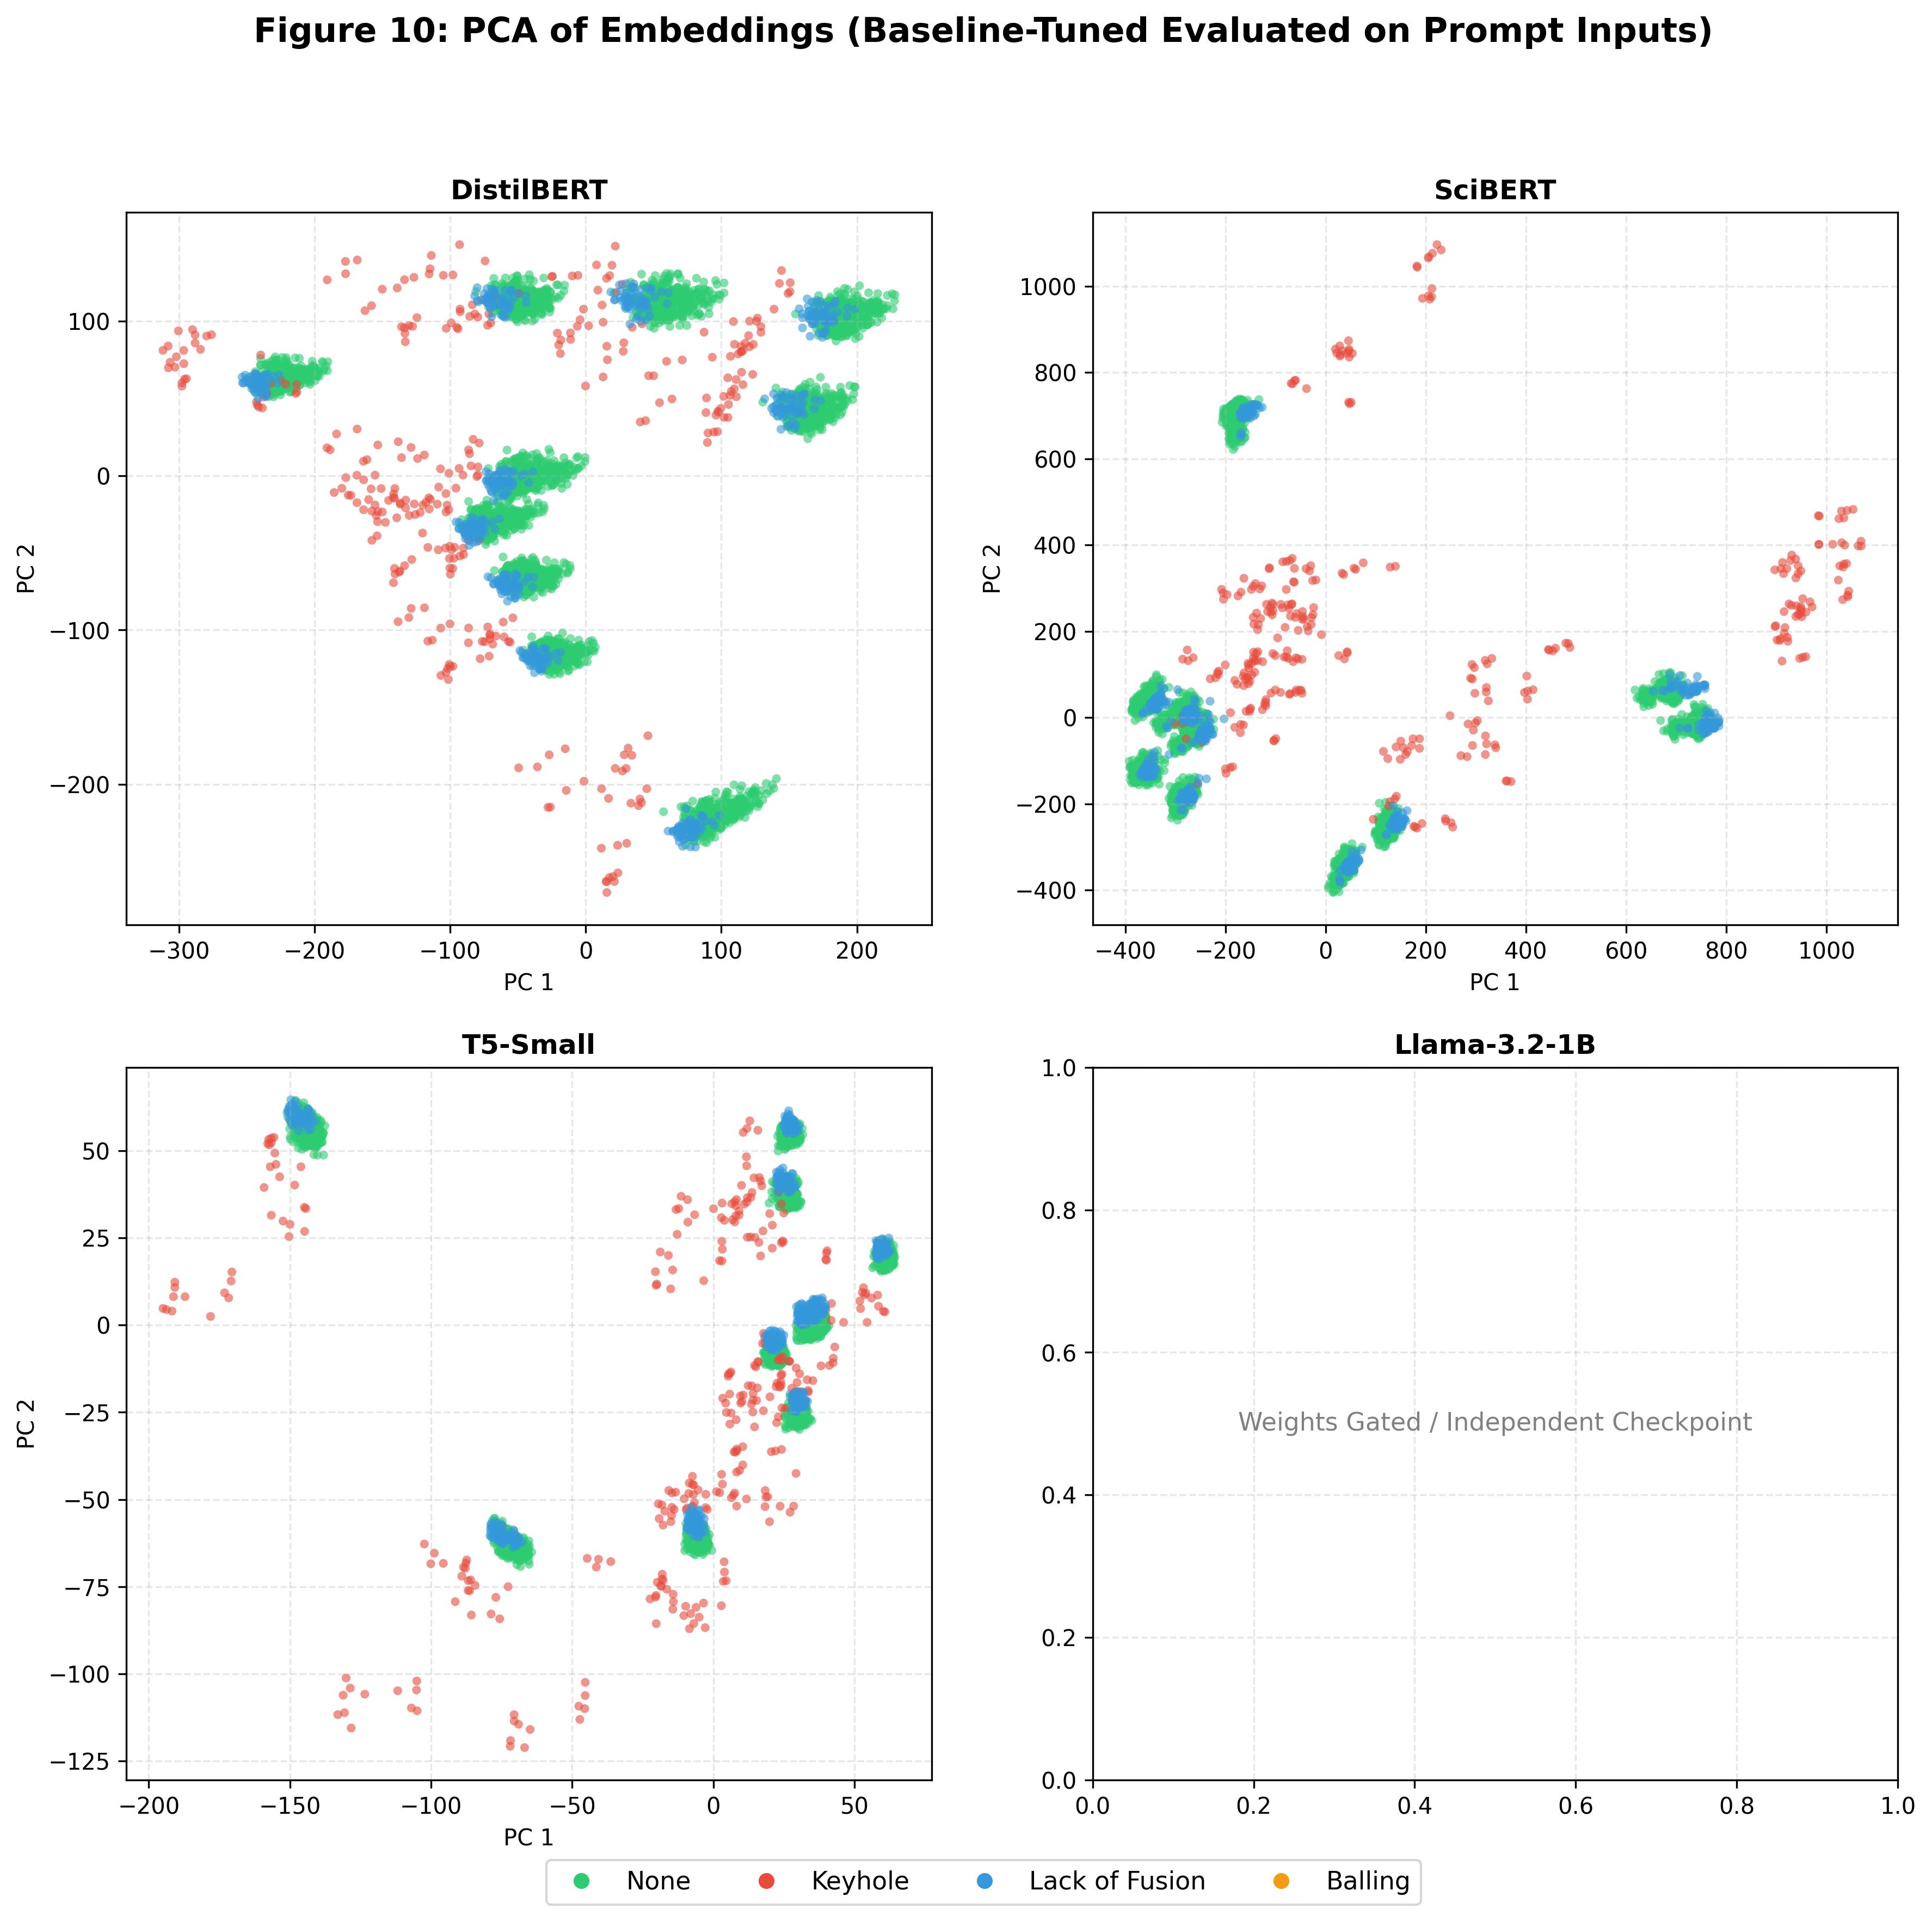

In [5]:
from IPython.display import Image, display
fig10_path = Path('../reports/figures/fig10_pca_out_of_format_embeddings.png')
if fig10_path.exists():
    print('Displaying Figure 10 (Out-of-Format Prompt PCA):')
    display(Image(filename=str(fig10_path)))
else:
    print('Figure 10 available in reports/figures/')